In [239]:
import sys
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import MultiLabelBinarizer, normalize
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

PROJECT_ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "pyproject.toml").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.load_dataset import laod_dataframes

CONFIG = dict(seed=42, max_users=6000, eval_per_segment=150, k=10,
              candidates_per_model=60, neighbors=40, factors=24,
              epochs=5, batch_size=2048, learning_rate=0.003)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(2)

set_seed(CONFIG["seed"])




0. загрузка данных

In [240]:
dataset_dict = laod_dataframes()

df_books = dataset_dict["df_books"]
df_ratings = dataset_dict["df_ratings"]
df_book_tags = dataset_dict["df_book_tags"]
df_tags = dataset_dict["df_tags"]
df_to_read = dataset_dict["df_to_read"]

Этап 1. Подготовка данных
1.1. Получаем уже загруженные таблицы

In [241]:
for name, df in dataset_dict.items():
    print(f"{name}: {df.shape}")
    print(df.columns.tolist())
    print("-" * 50)

df_books: (10000, 23)
['id', 'book_id', 'best_book_id', 'work_id', 'books_count', 'isbn', 'isbn13', 'authors', 'original_publication_year', 'original_title', 'title', 'language_code', 'average_rating', 'ratings_count', 'work_ratings_count', 'work_text_reviews_count', 'ratings_1', 'ratings_2', 'ratings_3', 'ratings_4', 'ratings_5', 'image_url', 'small_image_url']
--------------------------------------------------
df_ratings: (981756, 3)
['book_id', 'user_id', 'rating']
--------------------------------------------------
df_book_tags: (999912, 3)
['goodreads_book_id', 'tag_id', 'count']
--------------------------------------------------
df_tags: (34252, 2)
['tag_id', 'tag_name']
--------------------------------------------------
df_to_read: (912705, 2)
['user_id', 'book_id']
--------------------------------------------------


1.2. Очистка данных

In [242]:

import numpy as np
import pandas as pd

ratings = df_ratings[
    ["user_id", "book_id", "rating"]
].copy()

ratings = ratings.dropna()
ratings = ratings.drop_duplicates(
    subset=["user_id", "book_id"],
    keep="last"
)

ratings = ratings[
    ratings["book_id"].isin(df_books["book_id"])
]

ratings = ratings[
    ratings["rating"].between(1, 5)
]

print("Количество взаимодействий:", len(ratings))
print("Пользователей:", ratings["user_id"].nunique())
print("Книг:", ratings["book_id"].nunique())


Количество взаимодействий: 79531
Пользователей: 28906
Книг: 812


1.3. Разделение на train и test

In [243]:

from sklearn.model_selection import train_test_split

rng = np.random.default_rng(42)

train_parts = []
test_parts = []

for user_id, group in ratings.groupby("user_id"):
    if len(group) < 5:
        train_parts.append(group)
        continue

    train_idx, test_idx = train_test_split(
        group.index.to_numpy(),
        test_size=0.2,
        random_state=42
    )

    train_parts.append(ratings.loc[train_idx])
    test_parts.append(ratings.loc[test_idx])

train_df = pd.concat(train_parts, ignore_index=True)
test_df = pd.concat(test_parts, ignore_index=True)

print("Train:", train_df.shape)
print("Test:", test_df.shape)


Train: (70551, 3)
Test: (8980, 3)


In [244]:

user_history = (
    train_df.groupby("user_id")["book_id"]
    .agg(set)
    .to_dict()
)

# Только оценки 4 и 5 считаем релевантными
test_relevant = (
    test_df[test_df["rating"] >= 4]
    .groupby("user_id")["book_id"]
    .agg(set)
    .to_dict()
)

print("Пользователей с релевантными книгами:",
      len(test_relevant))


Пользователей с релевантными книгами: 3679


Этап 2. Модель популярности (Popularity-Based)
2.1. Обучение модели

In [245]:

book_popularity = (
    train_df.groupby("book_id")
    .agg(
        mean_rating=("rating", "mean"),
        ratings_count=("rating", "count")
    )
    .reset_index()
)

# Минимальное число оценок для оценки популярности
min_ratings = 50

popular_books = (
    book_popularity[
        book_popularity["ratings_count"] >= min_ratings
    ]
    .sort_values(
        ["mean_rating", "ratings_count"],
        ascending=False
    )
)

popular_books.head()


,book_id,mean_rating,ratings_count
769,9566,4.777778,99
354,4708,4.666667,93
771,9569,4.625000,96
291,3885,4.560440,91
762,9531,4.557143,70


2.2. Функция рекомендаций

In [246]:

def recommend_popular(user_id, N=10):
    seen_books = user_history.get(user_id, set())

    recommendations = popular_books[
        ~popular_books["book_id"].isin(seen_books)
    ]

    return recommendations["book_id"].head(N).tolist()


In [247]:

user_id = train_df["user_id"].iloc[0]

recommended_ids = recommend_popular(user_id, N=5)

df_books[
    df_books["book_id"].isin(recommended_ids)
][["book_id", "title", "average_rating"]]


,book_id,title,average_rating
1298,9566,Still Life with Woodpecker,4.04
3254,4708,The Beautiful and Damned,3.75
3909,9531,Peter and the Shadow Thieves (Peter and the St...,4.15
4871,9569,Villa Incognito,3.65
6662,3885,The Taste of Home Cookbook,4.25


Этап 3. Контентная модель (Content-Based Filtering)

In [248]:

# 1. Объединяем теги с их названиями
book_tags = df_book_tags.merge(
    df_tags,
    on="tag_id",
    how="left"
)

# 2. Выбираем 10 наиболее значимых тегов для каждой книги
book_tags = (
    book_tags
    .sort_values("count", ascending=False)
    .groupby("goodreads_book_id")
    .head(10)
    .copy()
)

# 3. Подготавливаем названия тегов
book_tags["tag_name"] = (
    book_tags["tag_name"]
    .fillna("")
    .str.replace("-", " ", regex=False)
)

# 4. Объединяем теги в одну строку для каждой книги
tags_aggregated = (
    book_tags.groupby("goodreads_book_id")["tag_name"]
    .agg(" ".join)
    .reset_index()
)

# 5. Создаём таблицу с текстовым описанием книг
books_content = df_books[
    ["id", "book_id", "title", "original_title"]
].copy()

# 6. Объединяем книги с тегами по разным названиям ключа
books_content = books_content.merge(
    tags_aggregated,
    left_on="book_id",
    right_on="goodreads_book_id",
    how="left"
)

# 7. Формируем текст для TF-IDF
books_content["content"] = (
    books_content["original_title"]
    .fillna(books_content["title"])
    .fillna("")
    + " "
    + books_content["tag_name"].fillna("")
)

display(books_content[["id", "title", "content"]].head())


,id,title,content
0,1,"The Hunger Games (The Hunger Games, #1)",The Hunger Games favorites currently reading y...
1,2,Harry Potter and the Sorcerer's Stone (Harry P...,Harry Potter and the Philosopher's Stone to re...
2,3,"Twilight (Twilight, #1)",Twilight young adult fantasy favorites vampire...
3,4,To Kill a Mockingbird,To Kill a Mockingbird classics favorites to re...
4,5,The Great Gatsby,The Great Gatsby classics favorites fiction cl...


In [249]:
df_books

,id,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,7130616,7130616,7392860,19,441019455,9.780441e+12,Ilona Andrews,2010.0,Bayou Moon,...,17204,18856,1180,105,575,3538,7860,6778,https://images.gr-assets.com/books/1307445460m...,https://images.gr-assets.com/books/1307445460s...
9996,9997,208324,208324,1084709,19,067973371X,9.780680e+12,Robert A. Caro,1990.0,Means of Ascent,...,12582,12952,395,303,551,1737,3389,6972,https://s.gr-assets.com/assets/nophoto/book/11...,https://s.gr-assets.com/assets/nophoto/book/50...
9997,9998,77431,77431,2393986,60,039330762X,9.780393e+12,Patrick O'Brian,1977.0,The Mauritius Command,...,9421,10733,374,11,111,1191,4240,5180,https://images.gr-assets.com/books/1455373531m...,https://images.gr-assets.com/books/1455373531s...
9998,9999,8565083,8565083,13433613,7,61711527,9.780062e+12,Peggy Orenstein,2011.0,Cinderella Ate My Daughter: Dispatches from th...,...,11279,11994,1988,275,1002,3765,4577,2375,https://images.gr-assets.com/books/1279214118m...,https://images.gr-assets.com/books/1279214118s...


3.2. TF-IDF
TF-IDF присваивает словам веса: распространённые слова становятся менее важными, а характерные для конкретной книги или группы книг — более значимыми.

In [250]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=20000,
    ngram_range=(1, 2)
)

tfidf_matrix = tfidf.fit_transform(
    books_content["content"]
)

print("Размер TF-IDF матрицы:", tfidf_matrix.shape)


Размер TF-IDF матрицы: (10000, 20000)


In [251]:

from sklearn.metrics.pairwise import cosine_similarity

book_id_to_idx = pd.Series(
    np.arange(len(books_content)),
    index=books_content["book_id"]
)

def get_similar_books(book_id, N=10):
    if book_id not in book_id_to_idx:
        return []

    idx = int(book_id_to_idx[book_id])

    similarities = cosine_similarity(
        tfidf_matrix[idx],
        tfidf_matrix
    ).ravel()

    similarities[idx] = -1

    top_indices = np.argsort(similarities)[::-1][:N]

    return (
        books_content.iloc[top_indices]["book_id"]
        .tolist()
    )


In [252]:

book_id = 1

similar_ids = get_similar_books(book_id, N=5)

df_books[
    df_books["book_id"].isin(similar_ids)
][["book_id", "title"]]


,book_id,title
1,3,Harry Potter and the Sorcerer's Stone (Harry P...
17,5,Harry Potter and the Prisoner of Azkaban (Harr...
22,15881,Harry Potter and the Chamber of Secrets (Harry...
24,136251,Harry Potter and the Deathly Hallows (Harry Po...
3752,10,"Harry Potter Collection (Harry Potter, #1-6)"


In [253]:

from sklearn.preprocessing import normalize

positive_history = (
    train_df[train_df["rating"] >= 4]
    .groupby("user_id")["book_id"]
    .agg(list)
    .to_dict()
)

def recommend_content(user_id, N=10):
    liked_books = positive_history.get(user_id, [])

    if not liked_books:
        return recommend_popular(user_id, N)

    indices = [
        int(book_id_to_idx[book_id])
        for book_id in liked_books
        if book_id in book_id_to_idx
    ]

    if not indices:
        return recommend_popular(user_id, N)

    # Усредняем векторы понравившихся книг
    user_profile = np.asarray(
        tfidf_matrix[indices].mean(axis=0)
    )

    user_profile = normalize(user_profile)

    similarities = cosine_similarity(
        user_profile,
        tfidf_matrix
    ).ravel()

    # Исключаем книги из истории пользователя
    seen = user_history.get(user_id, set())

    seen_indices = [
        int(book_id_to_idx[b])
        for b in seen
        if b in book_id_to_idx
    ]

    similarities[seen_indices] = -1

    top_indices = np.argsort(similarities)[::-1][:N]

    return (
        books_content.iloc[top_indices]["book_id"]
        .tolist()
    )


In [254]:

recommend_content(user_id=1, N=10)


[9566, 4708, 9569, 3885, 9531, 2865, 2767, 4373, 5344, 3698]

Этап 4. Коллаборативная фильтрация (Item-Based CF)

In [255]:

from scipy.sparse import csr_matrix

user_ids = np.sort(train_df["user_id"].unique())
book_ids = np.sort(df_books["book_id"].unique())

user_to_idx = {
    user_id: idx
    for idx, user_id in enumerate(user_ids)
}

book_to_idx = {
    book_id: idx
    for idx, book_id in enumerate(book_ids)
}

rows = train_df["user_id"].map(user_to_idx).to_numpy()
cols = train_df["book_id"].map(book_to_idx).to_numpy()

interaction_matrix = csr_matrix(
    (
        train_df["rating"].to_numpy(dtype=np.float32),
        (rows, cols)
    ),
    shape=(len(user_ids), len(book_ids)),
    dtype=np.float32
)

print("Матрица взаимодействий:", interaction_matrix.shape)


Матрица взаимодействий: (28906, 10000)


In [256]:

from sklearn.metrics.pairwise import cosine_similarity

item_matrix = interaction_matrix.T.tocsr()

item_similarity = cosine_similarity(
    item_matrix,
    dense_output=False
)

item_similarity.setdiag(0)
item_similarity.eliminate_zeros()

print("Матрица сходства:", item_similarity.shape)


Матрица сходства: (10000, 10000)


In [257]:

def recommend_item_cf(user_id, N=10):
    if user_id not in user_to_idx:
        return recommend_popular(user_id, N)

    user_idx = user_to_idx[user_id]
    user_ratings = interaction_matrix.getrow(user_idx)

    # Взвешенная сумма похожестей
    weighted_scores = (
        item_similarity @ user_ratings.T
    ).toarray().ravel()

    # Нормировка на сумму похожестей
    observed = user_ratings.copy()
    observed.data = np.ones_like(observed.data)

    normalizer = (
        item_similarity @ observed.T
    ).toarray().ravel()

    scores = np.divide(
        weighted_scores,
        normalizer,
        out=np.zeros_like(weighted_scores),
        where=normalizer > 0
    )

    # Не рекомендуем уже оцененные книги
    scores[user_ratings.indices] = -np.inf

    # Исключаем книги, для которых нет соседей
    scores[normalizer <= 0] = -np.inf

    valid_indices = np.where(np.isfinite(scores))[0]

    top_indices = valid_indices[
        np.argsort(scores[valid_indices])[::-1][:N]
    ]

    recommendations = book_ids[top_indices].tolist()

    if len(recommendations) < N:
        fallback = recommend_popular(user_id, N)
        recommendations += [
            b for b in fallback
            if b not in recommendations
        ][:N - len(recommendations)]

    return recommendations


In [258]:

recommend_item_cf(user_id=1, N=10)


[9566, 4708, 9569, 3885, 9531, 2865, 2767, 4373, 5344, 3698]

Этап 5. Матричная факторизация (SVD)

In [259]:

from surprise import SVD, Dataset, Reader

reader = Reader(rating_scale=(1, 5))

dataset = Dataset.load_from_df(
    train_df[["user_id", "book_id", "rating"]],
    reader
)

trainset = dataset.build_full_trainset()

svd_model = SVD(
    n_factors=50,
    n_epochs=30,
    lr_all=0.005,
    reg_all=0.02,
    random_state=42
)

svd_model.fit(trainset)



prediction = svd_model.predict(
    uid=1,
    iid=10
)

print("Предсказанная оценка:", prediction.est)


In [260]:

def recommend_svd(user_id, N=10):
    seen_books = user_history.get(user_id, set())

    candidates = [
        book_id
        for book_id in book_ids
        if book_id not in seen_books
    ]

    predictions = [
        (
            book_id,
            svd_model.predict(
                uid=int(user_id),
                iid=int(book_id)
            ).est
        )
        for book_id in candidates
    ]

    predictions.sort(
        key=lambda x: x[1],
        reverse=True
    )

    return [
        book_id
        for book_id, score in predictions[:N]
    ]


In [261]:

recommend_svd(user_id=1, N=10)


[np.int64(9566),
 np.int64(9569),
 np.int64(4708),
 np.int64(2767),
 np.int64(2865),
 np.int64(3885),
 np.int64(9531),
 np.int64(5344),
 np.int64(7039),
 np.int64(9712)]

In [262]:
recommend_popular(user_id, N=10)
recommend_content(user_id, N=10)
recommend_item_cf(user_id, N=10)
recommend_svd(user_id, N=10)

[np.int64(9566),
 np.int64(9569),
 np.int64(7039),
 np.int64(3885),
 np.int64(4708),
 np.int64(3836),
 np.int64(5346),
 np.int64(5344),
 np.int64(2767),
 np.int64(2)]

In [263]:

import numpy as np

def precision_at_k(actual, predicted, k=10):
    if k <= 0:
        return 0.0

    actual = set(actual)
    predicted = list(dict.fromkeys(predicted))[:k]

    hits = len(actual.intersection(predicted))

    return hits / k


def recall_at_k(actual, predicted, k=10):
    actual = set(actual)

    if not actual or k <= 0:
        return 0.0

    predicted = list(dict.fromkeys(predicted))[:k]

    hits = len(actual.intersection(predicted))

    return hits / len(actual)


def ndcg_at_k(actual, predicted, k=10):
    actual = set(actual)

    if not actual or k <= 0:
        return 0.0

    predicted = list(dict.fromkeys(predicted))[:k]

    relevance = np.array([
        1 if book_id in actual else 0
        for book_id in predicted
    ])

    positions = np.arange(1, len(relevance) + 1)

    dcg = np.sum(
        relevance / np.log2(positions + 1)
    )

    ideal_hits = min(len(actual), k)

    ideal_positions = np.arange(1, ideal_hits + 1)

    idcg = np.sum(
        1 / np.log2(ideal_positions + 1)
    )

    return float(dcg / idcg)


In [264]:

def evaluate_model(
    recommend_fn,
    users,
    test_relevant,
    k=10
):
    results = []

    for user_id in users:
        actual = test_relevant[user_id]

        predicted = recommend_fn(user_id, N=k)

        results.append({
            "user_id": user_id,
            "precision": precision_at_k(
                actual, predicted, k
            ),
            "recall": recall_at_k(
                actual, predicted, k
            ),
            "ndcg": ndcg_at_k(
                actual, predicted, k
            )
        })

    return pd.DataFrame(results)


# Берём одинаковых пользователей для всех моделей
rng = np.random.default_rng(42)

eval_users = rng.choice(
    list(test_relevant.keys()),
    size=min(200, len(test_relevant)),
    replace=False
).tolist()


In [265]:

models = {
    "Popularity": recommend_popular,
    "Content-Based": recommend_content,
    "Item-Based CF": recommend_item_cf,
    "SVD": recommend_svd
}

comparison_results = []

for model_name, recommend_fn in models.items():
    metrics = evaluate_model(
        recommend_fn,
        eval_users,
        test_relevant,
        k=10
    )

    comparison_results.append({
        "Model": model_name,
        "Precision@10": metrics["precision"].mean(),
        "Recall@10": metrics["recall"].mean(),
        "nDCG@10": metrics["ndcg"].mean()
    })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values(
        "nDCG@10",
        ascending=False
    )
)


,Model,Precision@10,Recall@10,nDCG@10
3,SVD,0.0020,0.009500,0.004440
0,Popularity,0.0010,0.007500,0.004177
2,Item-Based CF,0.0020,0.008500,0.003765
1,Content-Based,0.0015,0.005417,0.003241


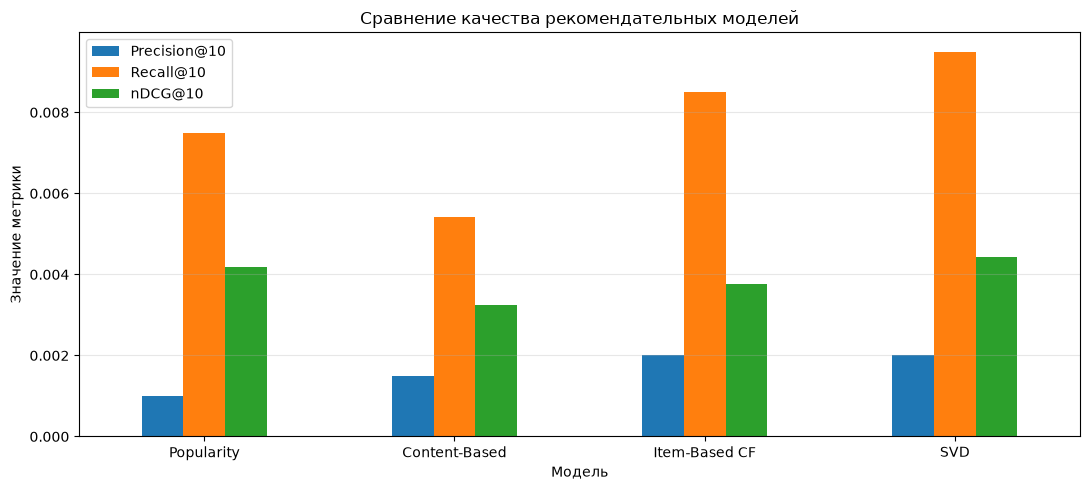

In [266]:

import matplotlib.pyplot as plt

comparison_df.set_index("Model")[
    ["Precision@10", "Recall@10", "nDCG@10"]
].plot(
    kind="bar",
    figsize=(11, 5),
    rot=0
)

plt.title("Сравнение качества рекомендательных моделей")
plt.xlabel("Модель")
plt.ylabel("Значение метрики")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Построение гибридной системы

Стратегия объединения моделей:
Взвешенное усреднение предсказаний разных моделей.
Разделение пользователей по типам (новые/активные).
Комбинирование персонализированных и популярных рекомендаций.

In [267]:
global_mean = train_df["rating"].mean()
m = 50

book_popularity = (
    train_df.groupby("book_id")
    .agg(
        mean_rating=("rating", "mean"),
        ratings_count=("rating", "count")
    )
    .reset_index()
)

book_popularity["score"] = (
    book_popularity["ratings_count"]
    / (book_popularity["ratings_count"] + m)
    * book_popularity["mean_rating"]
    +
    m / (book_popularity["ratings_count"] + m)
    * global_mean
)

book_popularity = book_popularity.sort_values(
    "score", ascending=False
)


def recommend_popular(user_id, N=10):
    seen = user_history.get(user_id, set())

    candidates = book_popularity[
        ~book_popularity["book_id"].isin(seen)
    ].head(N)

    return [
        {
            "book_id": int(row.book_id),
            "score": float(row.score)
        }
        for row in candidates.itertuples()
    ]

In [268]:
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize
import numpy as np

book_id_to_idx = {
    int(book_id): idx
    for idx, book_id in enumerate(books_content["book_id"])
}

positive_history = (
    train_df[train_df["rating"] >= 4]
    .groupby("user_id")["book_id"]
    .agg(list)
    .to_dict()
)


def recommend_content(user_id, N=10):
    liked_books = positive_history.get(user_id, [])

    indices = [
        book_id_to_idx[book_id]
        for book_id in liked_books
        if book_id in book_id_to_idx
    ]

    if not indices:
        return recommend_popular(user_id, N)

    user_profile = np.asarray(
        tfidf_matrix[indices].mean(axis=0)
    )

    user_profile = normalize(user_profile)

    scores = cosine_similarity(
        user_profile, tfidf_matrix
    ).ravel()

    seen = user_history.get(user_id, set())

    for book_id in seen:
        idx = book_id_to_idx.get(book_id)
        if idx is not None:
            scores[idx] = -np.inf

    top_indices = np.argsort(scores)[::-1][:N]

    return [
        {
            "book_id": int(books_content.iloc[idx]["book_id"]),
            "score": float(scores[idx])
        }
        for idx in top_indices
        if np.isfinite(scores[idx])
    ]

In [269]:
def recommend_item_cf(user_id, N=10):
    if user_id not in user_to_idx:
        return recommend_popular(user_id, N)

    user_idx = user_to_idx[user_id]
    user_ratings = interaction_matrix.getrow(user_idx)

    weighted_scores = (
        item_similarity @ user_ratings.T
    ).toarray().ravel()

    observed = user_ratings.copy()
    observed.data = np.ones_like(observed.data)

    normalizer = (
        item_similarity @ observed.T
    ).toarray().ravel()

    scores = np.divide(
        weighted_scores,
        normalizer,
        out=np.zeros_like(weighted_scores),
        where=normalizer > 0
    )

    scores[normalizer <= 0] = -np.inf
    scores[user_ratings.indices] = -np.inf

    valid_indices = np.where(np.isfinite(scores))[0]

    top_indices = valid_indices[
        np.argsort(scores[valid_indices])[::-1][:N]
    ]

    return [
        {
            "book_id": int(book_ids[idx]),
            "score": float(scores[idx])
        }
        for idx in top_indices
    ]

In [270]:
def recommend_svd(user_id, N=10):
    seen = user_history.get(user_id, set())

    candidates = [
        int(book_id)
        for book_id in book_ids
        if book_id not in seen
    ]

    predictions = [
        {
            "book_id": book_id,
            "score": float(
                svd_model.predict(
                    uid=int(user_id),
                    iid=book_id
                ).est
            )
        }
        for book_id in candidates
    ]

    predictions.sort(
        key=lambda x: x["score"],
        reverse=True
    )

    return predictions[:N]

In [271]:
models = {
    "Popularity": recommend_popular,
    "Content-Based": recommend_content,
    "Item-Based CF": recommend_item_cf,
    "SVD": recommend_svd
}

user_id = 1

for model_name, recommend_fn in models.items():
    print(f"\n{model_name}")

    recommendations = recommend_fn(user_id, N=5)

    display(pd.DataFrame(recommendations))


Popularity


,book_id,score
0,9566,4.470189
1,4708,4.385022
2,9569,4.363412
3,3885,4.312470
4,2865,4.307559



Content-Based


,book_id,score
0,9566,4.470189
1,4708,4.385022
2,9569,4.363412
3,3885,4.312470
4,2865,4.307559



Item-Based CF


,book_id,score
0,9566,4.470189
1,4708,4.385022
2,9569,4.363412
3,3885,4.312470
4,2865,4.307559



SVD


,book_id,score
0,9566,4.762116
1,9569,4.628975
2,4708,4.609305
3,2767,4.565989
4,2865,4.565684


In [272]:
def show_recommendations(user_id, model_name, N=10):
    recommendations = models[model_name](user_id, N)

    result = pd.DataFrame(
        recommendations,
        columns=["book_id", "score"]
    )

    result = result.merge(
        df_books[["id", "title", "authors"]],
        left_on="book_id",
        right_on="id",
        how="left"
    )

    return result[
        ["book_id", "title", "authors", "score"]
    ]


display(
    show_recommendations(
        user_id=1,
        model_name="SVD",
        N=10
    )
)

,book_id,title,authors,score
0,9566,Attack of the Deranged Mutant Killer Monster S...,Bill Watterson,4.762116
1,9569,The Hate U Give,Angie Thomas,4.628975
2,4708,BookRags Summary: A Storm of Swords,BookRags,4.609305
3,2767,"Saga, Vol. 3 (Saga, #3)","Brian K. Vaughan, Fiona Staples",4.565989
4,2865,"The Gashlycrumb Tinies (The Vinegar Works, #1)",Edward Gorey,4.565684
5,3885,Born a Crime: Stories From a South African Chi...,Trevor Noah,4.557005
6,9531,Crush,Richard Siken,4.518464
7,5344,"A Game of Thrones: Comic Book, Issue 1","Daniel Abraham, George R.R. Martin, Tommy Patt...",4.498090
8,7039,The Brothers Lionheart,"Astrid Lindgren, Ilon Wikland, Jill M. Morgan",4.493167
9,9712,"Magic Binds (Kate Daniels, #9)",Ilona Andrews,4.485774


In [273]:
user_id = 1

pop_scores = recommend_popular(user_id, N=100)
content_scores = recommend_content(user_id, N=100)
item_scores = recommend_item_cf(user_id, N=100)
svd_scores = recommend_svd(user_id, N=100)

In [274]:
def get_recommended_ids(recommendations):
    return [
        item["book_id"]
        for item in recommendations
    ]

In [275]:
def evaluate_model(
    recommend_fn,
    users,
    test_relevant,
    k=10
):
    results = []

    for user_id in users:
        actual = test_relevant[user_id]

        predicted = get_recommended_ids(
                        recommend_fn(user_id, N=k)
                    )

        results.append({
            "user_id": user_id,
            "precision": precision_at_k(
                actual, predicted, k
            ),
            "recall": recall_at_k(
                actual, predicted, k
            ),
            "ndcg": ndcg_at_k(
                actual, predicted, k
            )
        })

    return pd.DataFrame(results)


In [276]:

DEFAULT_WEIGHTS = {
    "pop": 0.1,
    "content": 0.2,
    "item": 0.3,
    "svd": 0.4
}

import numpy as np
import pandas as pd

def normalize_scores(recommendations):
    if not recommendations:
        return {}

    df = pd.DataFrame(recommendations)

    min_score = df["score"].min()
    max_score = df["score"].max()

    if np.isclose(min_score, max_score):
        df["normalized_score"] = 1.0
    else:
        df["normalized_score"] = (
            (df["score"] - min_score)
            / (max_score - min_score)
        )

    return dict(zip(
        df["book_id"],
        df["normalized_score"]
    ))

def recommend_hybrid(user_id, N=10, weights=None, candidates_k=100):
    if weights is None:
        weights = DEFAULT_WEIGHTS

    if not np.isclose(sum(weights.values()), 1.0):
        raise ValueError("Сумма весов должна равняться 1")

    # Получаем рекомендации базовых моделей
    recommendations = {
        "pop": recommend_popular(user_id, N=candidates_k),
        "content": recommend_content(user_id, N=candidates_k),
        "item": recommend_item_cf(user_id, N=candidates_k),
        "svd": recommend_svd(user_id, N=candidates_k)
    }

    # Нормализуем scores
    normalized = {
        name: normalize_scores(recs)
        for name, recs in recommendations.items()
    }

    # Объединяем книги
    candidate_ids = set().union(
        *(scores.keys() for scores in normalized.values())
    )

    # Исключаем книги из обучающей истории
    seen = user_history.get(user_id, set())
    candidate_ids -= seen

    results = []

    for book_id in candidate_ids:
        score = sum(
            weights[name] * normalized[name].get(book_id, 0.0)
            for name in weights
        )

        results.append({
            "book_id": int(book_id),
            "score": float(score)
        })

    results.sort(
        key=lambda x: (-x["score"], x["book_id"])
    )

    return results[:N]


In [277]:
hybrid_recs = recommend_hybrid(user_id=1, N=10)

pd.DataFrame(hybrid_recs)

,book_id,score
0,9566,1.000000
1,4708,0.764516
2,9569,0.745409
3,3885,0.618069
4,2865,0.616653
5,2767,0.598393
6,5344,0.537135
7,9531,0.522510
8,7039,0.515871
9,9712,0.514731


Этап 4. Hybrid Adaptive

In [278]:
user_activity = (
    train_df.groupby("user_id")
    .size()
    .to_dict()
)

In [279]:

def get_user_type(user_id):
    n_ratings = user_activity.get(user_id, 0)

    if n_ratings < 5:
        return "new"
    elif n_ratings < 50:
        return "regular"
    else:
        return "active"


In [280]:
user_id = 1

print("Количество оценок:", user_activity.get(user_id, 0))
print("Тип пользователя:", get_user_type(user_id))

Количество оценок: 0
Тип пользователя: new


In [281]:

ADAPTIVE_WEIGHTS = {
    "new": {
        "pop": 0.65,
        "content": 0.25,
        "item": 0.05,
        "svd": 0.05
    },
    "regular": {
        "pop": 0.15,
        "content": 0.35,
        "item": 0.25,
        "svd": 0.25
    },
    "active": {
        "pop": 0.05,
        "content": 0.15,
        "item": 0.35,
        "svd": 0.45
    }
}


In [282]:
recommend_hybrid(
    user_id,
    N=10,
    weights=None,
    candidates_k=100
)

[{'book_id': 9566, 'score': 1.0},
 {'book_id': 4708, 'score': 0.764515822512438},
 {'book_id': 9569, 'score': 0.7454088978711904},
 {'book_id': 3885, 'score': 0.6180686740855309},
 {'book_id': 2865, 'score': 0.6166534473243835},
 {'book_id': 2767, 'score': 0.598393177457263},
 {'book_id': 5344, 'score': 0.5371350997901642},
 {'book_id': 9531, 'score': 0.5225102958511766},
 {'book_id': 7039, 'score': 0.5158713780134471},
 {'book_id': 9712, 'score': 0.5147310653309188}]

In [283]:

def recommend_hybrid_adaptive(user_id, N=10):
    user_type = get_user_type(user_id)

    # Холодный старт: пользователь без истории
    if user_activity.get(user_id, 0) == 0:
        return recommend_popular(user_id, N=N)

    weights = ADAPTIVE_WEIGHTS[user_type]

    return recommend_hybrid(
        user_id=user_id,
        N=N,
        weights=weights,
        candidates_k=100
    )


In [284]:
user_segments = pd.DataFrame({
    "user_id": list(user_activity.keys()),
    "ratings_count": list(user_activity.values())
})

user_segments["user_type"] = (
    user_segments["user_id"].apply(get_user_type)
)

display(
    user_segments["user_type"].value_counts()
)

user_type
new        26588
regular     2318
Name: count, dtype: int64

In [285]:
user_id = 1

print("Тип:", get_user_type(user_id))
print("Веса:", ADAPTIVE_WEIGHTS[get_user_type(user_id)])

recommendations = recommend_hybrid_adaptive(user_id, N=10)

display(pd.DataFrame(recommendations))

Тип: new
Веса: {'pop': 0.65, 'content': 0.25, 'item': 0.05, 'svd': 0.05}


,book_id,score
0,9566,4.470189
1,4708,4.385022
2,9569,4.363412
3,3885,4.312470
4,2865,4.307559
5,2767,4.295383
6,5344,4.286130
7,9712,4.277009
8,6862,4.276264
9,7039,4.274371


In [286]:
def show_adaptive_recommendations(user_id, N=10):
    recommendations = recommend_hybrid_adaptive(user_id, N)

    result = pd.DataFrame(recommendations)

    result = result.merge(
        df_books[["id", "title", "authors"]],
        left_on="book_id",
        right_on="id",
        how="left"
    )

    return result[
        ["book_id", "title", "authors", "score"]
    ]


display(show_adaptive_recommendations(user_id=1))

,book_id,title,authors,score
0,9566,Attack of the Deranged Mutant Killer Monster S...,Bill Watterson,4.470189
1,4708,BookRags Summary: A Storm of Swords,BookRags,4.385022
2,9569,The Hate U Give,Angie Thomas,4.363412
3,3885,Born a Crime: Stories From a South African Chi...,Trevor Noah,4.312470
4,2865,"The Gashlycrumb Tinies (The Vinegar Works, #1)",Edward Gorey,4.307559
5,2767,"Saga, Vol. 3 (Saga, #3)","Brian K. Vaughan, Fiona Staples",4.295383
6,5344,"A Game of Thrones: Comic Book, Issue 1","Daniel Abraham, George R.R. Martin, Tommy Patt...",4.286130
7,9712,"Magic Binds (Kate Daniels, #9)",Ilona Andrews,4.277009
8,6862,"March: Book One (March, #1)","John Lewis, Andrew Aydin, Nate Powell",4.276264
9,7039,The Brothers Lionheart,"Astrid Lindgren, Ilon Wikland, Jill M. Morgan",4.274371


In [287]:
hybrid_models = {
    "Hybrid Weighted": recommend_hybrid,
    "Hybrid Adaptive": recommend_hybrid_adaptive
}

hybrid_results = []

for name, model in hybrid_models.items():
    metrics = evaluate_model(
        recommend_fn=model,
        users=eval_users,
        test_relevant=test_relevant,
        k=10
    )

    hybrid_results.append({
        "Model": name,
        "Precision@10": metrics["precision"].mean(),
        "Recall@10": metrics["recall"].mean(),
        "nDCG@10": metrics["ndcg"].mean()
    })

hybrid_comparison = pd.DataFrame(hybrid_results)

display(hybrid_comparison)

,Model,Precision@10,Recall@10,nDCG@10
0,Hybrid Weighted,0.0010,0.007500,0.002428
1,Hybrid Adaptive,0.0015,0.009167,0.004747


In [288]:

segment_metrics = evaluate_model(
    recommend_fn=recommend_hybrid_adaptive,
    users=eval_users,
    test_relevant=test_relevant,
    k=10
)

segment_metrics["user_type"] = (
    segment_metrics["user_id"].map(get_user_type)
)

segment_report = (
    segment_metrics.groupby("user_type")
    .agg(
        users=("user_id", "count"),
        precision_at_10=("precision", "mean"),
        recall_at_10=("recall", "mean"),
        ndcg_at_10=("ndcg", "mean")
    )
    .reset_index()
)

display(segment_report)


,user_type,users,precision_at_10,recall_at_10,ndcg_at_10
0,new,84,0.001190,0.011905,0.007511
1,regular,116,0.001724,0.007184,0.002746


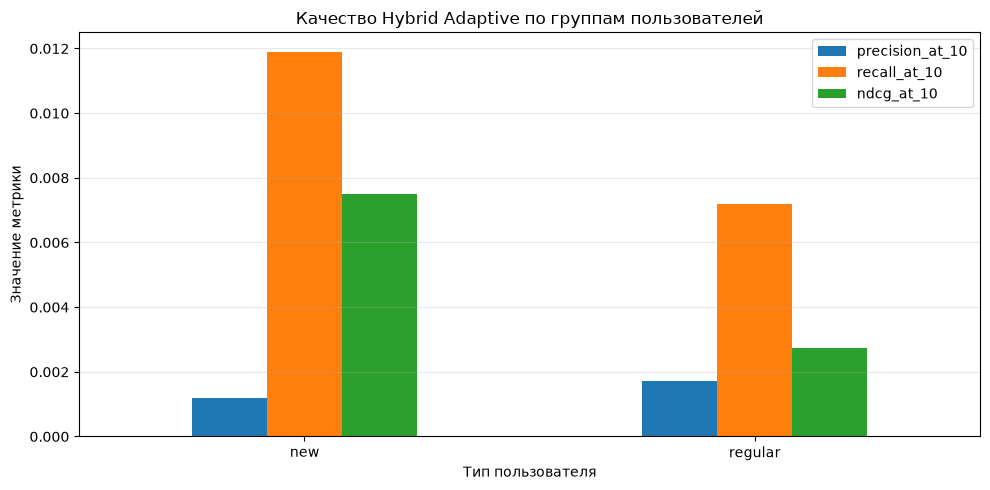

In [291]:
import matplotlib.pyplot as plt

segment_report.plot(
    x="user_type",
    y=["precision_at_10", "recall_at_10", "ndcg_at_10"],
    kind="bar",
    figsize=(10, 5),
    rot=0
)

plt.title("Качество Hybrid Adaptive по группам пользователей")
plt.xlabel("Тип пользователя")
plt.ylabel("Значение метрики")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Этап 5. Оптимизация Hybrid Adaptive с помощью Optuna

In [292]:
import optuna
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
K = 10
CANDIDATES_K = 100

MODEL_NAMES = ("pop", "content", "item", "svd")

In [293]:

# Сохраняем текущую обучающую выборку
train_original = train_df.copy()

fit_parts = []
val_parts = []

for user_id, group in train_original.groupby("user_id"):

    if len(group) < 5:
        fit_parts.append(group)
        continue

    fit_idx, val_idx = train_test_split(
        group.index.to_numpy(),
        test_size=0.2,
        random_state=RANDOM_STATE
    )

    fit_parts.append(train_original.loc[fit_idx])
    val_parts.append(train_original.loc[val_idx])

fit_df = pd.concat(fit_parts, ignore_index=True)
val_df = pd.concat(val_parts, ignore_index=True)

print("Fit:", fit_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)


Fit: (66042, 3)
Validation: (4509, 3)
Test: (8980, 3)


In [294]:

from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from surprise import SVD, Dataset, Reader

# Все функции recommend_* теперь работают с fit_df
train_df = fit_df.copy()

# 1. Истории пользователей
user_history = (
    train_df.groupby("user_id")["book_id"]
    .agg(set)
    .to_dict()
)

positive_history = (
    train_df[train_df["rating"] >= 4]
    .groupby("user_id")["book_id"]
    .agg(list)
    .to_dict()
)

user_activity = (
    train_df.groupby("user_id")
    .size()
    .to_dict()
)

# 2. Popularity
global_mean = train_df["rating"].mean()
m = 50

book_popularity = (
    train_df.groupby("book_id")
    .agg(
        mean_rating=("rating", "mean"),
        ratings_count=("rating", "count")
    )
    .reset_index()
)

book_popularity["score"] = (
    book_popularity["ratings_count"]
    / (book_popularity["ratings_count"] + m)
    * book_popularity["mean_rating"]
    +
    m / (book_popularity["ratings_count"] + m)
    * global_mean
)

book_popularity = book_popularity.sort_values(
    "score", ascending=False
)

# 3. Item-Based CF
user_ids = np.sort(train_df["user_id"].unique())

# ВАЖНО: внутренние ID книг из Goodbooks-10k
book_ids = np.sort(df_books["id"].unique())

user_to_idx = {
    uid: idx for idx, uid in enumerate(user_ids)
}

book_to_idx = {
    bid: idx for idx, bid in enumerate(book_ids)
}

rows = train_df["user_id"].map(user_to_idx).to_numpy()
cols = train_df["book_id"].map(book_to_idx).to_numpy()

interaction_matrix = csr_matrix(
    (
        train_df["rating"].to_numpy(dtype=np.float32),
        (rows, cols)
    ),
    shape=(len(user_ids), len(book_ids)),
    dtype=np.float32
)

item_matrix = interaction_matrix.T.tocsr()

item_similarity = cosine_similarity(
    item_matrix,
    dense_output=False
)

item_similarity.setdiag(0)
item_similarity.eliminate_zeros()
item_similarity = item_similarity.tocsr()

# 4. SVD
reader = Reader(rating_scale=(1, 5))

dataset = Dataset.load_from_df(
    train_df[["user_id", "book_id", "rating"]],
    reader
)

trainset = dataset.build_full_trainset()

svd_model = SVD(
    n_factors=50,
    n_epochs=30,
    lr_all=0.005,
    reg_all=0.02,
    random_state=RANDOM_STATE
)

svd_model.fit(trainset)

print("Базовые модели переобучены.")


Базовые модели переобучены.


In [295]:
val_relevant = (
    val_df[val_df["rating"] >= 4]
    .groupby("user_id")["book_id"]
    .agg(set)
    .to_dict()
)

In [296]:
segment_users = {
    "new": [],
    "regular": [],
    "active": []
}

for user_id in val_relevant:
    segment = get_user_type(user_id)
    segment_users[segment].append(user_id)

for segment, users in segment_users.items():
    print(f"{segment}: {len(users)} пользователей")

new: 776 пользователей
regular: 1099 пользователей
active: 0 пользователей


In [297]:

from tqdm.auto import tqdm

base_models = {
    "pop": recommend_popular,
    "content": recommend_content,
    "item": recommend_item_cf,
    "svd": recommend_svd
}

# Для начала ограничимся 200 пользователями на сегмент
rng = np.random.default_rng(RANDOM_STATE)

optimization_users = {}

for segment, users in segment_users.items():
    selected = rng.choice(
        users,
        size=min(200, len(users)),
        replace=False
    ).tolist() if users else []

    optimization_users[segment] = selected

all_optimization_users = [
    user_id
    for users in optimization_users.values()
    for user_id in users
]

# Один раз вычисляем нормализованные scores
prediction_cache = {}

for user_id in tqdm(all_optimization_users):
    prediction_cache[user_id] = {}

    for name, recommend_fn in base_models.items():
        recommendations = recommend_fn(
            user_id,
            N=CANDIDATES_K
        )

        prediction_cache[user_id][name] = (
            normalize_scores(recommendations)
        )

print("Предсказания закешированы.")


  0%|          | 0/400 [00:00<?, ?it/s]

Предсказания закешированы.


In [298]:
{
    "pop": {123: 0.85, 456: 0.70},
    "content": {123: 0.90, 789: 0.80},
    "item": {456: 0.95, 789: 0.65},
    "svd": {123: 0.92, 456: 0.88}
}

{'pop': {123: 0.85, 456: 0.7},
 'content': {123: 0.9, 789: 0.8},
 'item': {456: 0.95, 789: 0.65},
 'svd': {123: 0.92, 456: 0.88}}

In [299]:

def recommend_from_cache(user_id, weights, N=10):
    model_scores = prediction_cache[user_id]

    candidates = set().union(
        *(scores.keys() for scores in model_scores.values())
    )

    seen = user_history.get(user_id, set())
    candidates -= seen

    results = []

    for book_id in candidates:
        score = sum(
            weights[name] * model_scores[name].get(book_id, 0.0)
            for name in MODEL_NAMES
        )

        results.append((book_id, score))

    results.sort(key=lambda x: (-x[1], x[0]))

    return [
        book_id
        for book_id, score in results[:N]
    ]


In [300]:

def objective(trial, users):
    raw_weights = {
        name: trial.suggest_float(
            f"w_{name}", 0.0, 1.0
        )
        for name in MODEL_NAMES
    }

    total = sum(raw_weights.values())

    if total == 0:
        return 0.0

    weights = {
        name: value / total
        for name, value in raw_weights.items()
    }

    ndcg_scores = []

    for user_id in users:
        actual = val_relevant[user_id]

        predicted = recommend_from_cache(
            user_id,
            weights,
            N=K
        )

        score = ndcg_at_k(
            actual,
            predicted,
            k=K
        )

        ndcg_scores.append(score)

    return float(np.mean(ndcg_scores))


In [301]:

studies = {}
optimized_weights = {}

for segment, users in optimization_users.items():

    if not users:
        print(f"{segment}: нет пользователей, пропускаем")
        optimized_weights[segment] = ADAPTIVE_WEIGHTS[segment].copy()
        continue

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        ),
        study_name=f"hybrid_{segment}"
    )

    study.optimize(
        lambda trial: objective(trial, users),
        n_trials=50,
        show_progress_bar=True
    )

    studies[segment] = study

    best_params = study.best_params

    total = sum(best_params.values())

    optimized_weights[segment] = {
        name: best_params[f"w_{name}"] / total
        for name in MODEL_NAMES
    }

    print(f"\nСегмент: {segment}")
    print(f"Лучший nDCG@10: {study.best_value:.4f}")
    print("Оптимальные веса:", optimized_weights[segment])


  0%|          | 0/50 [00:00<?, ?it/s]


Сегмент: new
Лучший nDCG@10: 0.0156
Оптимальные веса: {'pop': 0.20415604092367098, 'content': 0.033852559235602694, 'item': 0.5335531962338274, 'svd': 0.22843820360689895}


  0%|          | 0/50 [00:00<?, ?it/s]


Сегмент: regular
Лучший nDCG@10: 0.0157
Оптимальные веса: {'pop': 0.009620455168903653, 'content': 0.48286483283492937, 'item': 0.26381636655265367, 'svd': 0.24369834544351335}
active: нет пользователей, пропускаем


In [302]:
weight_rows = []

for segment in optimized_weights:
    for model_name in MODEL_NAMES:
        weight_rows.append({
            "Segment": segment,
            "Model": model_name,
            "Original": ADAPTIVE_WEIGHTS[segment][model_name],
            "Optimized": optimized_weights[segment][model_name]
        })

weights_comparison = pd.DataFrame(weight_rows)

display(weights_comparison)

,Segment,Model,Original,Optimized
0,new,pop,0.65,0.204156
1,new,content,0.25,0.033853
2,new,item,0.05,0.533553
3,new,svd,0.05,0.228438
4,regular,pop,0.15,0.009620
5,regular,content,0.35,0.482865
6,regular,item,0.25,0.263816
7,regular,svd,0.25,0.243698
8,active,pop,0.05,0.050000
9,active,content,0.15,0.150000


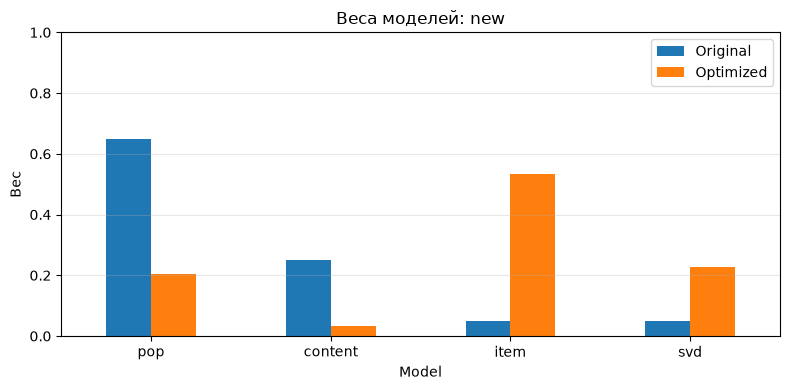

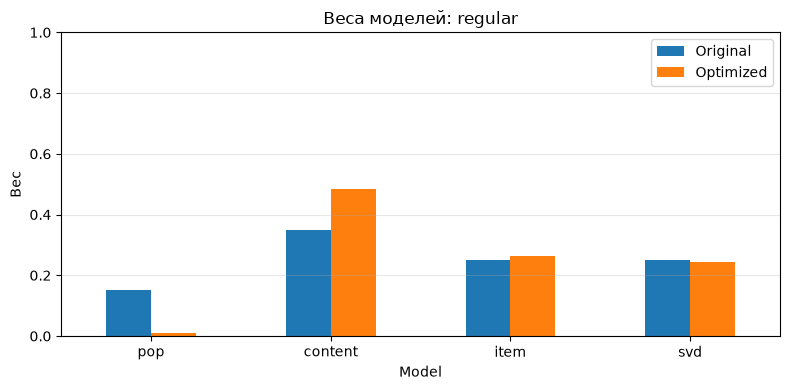

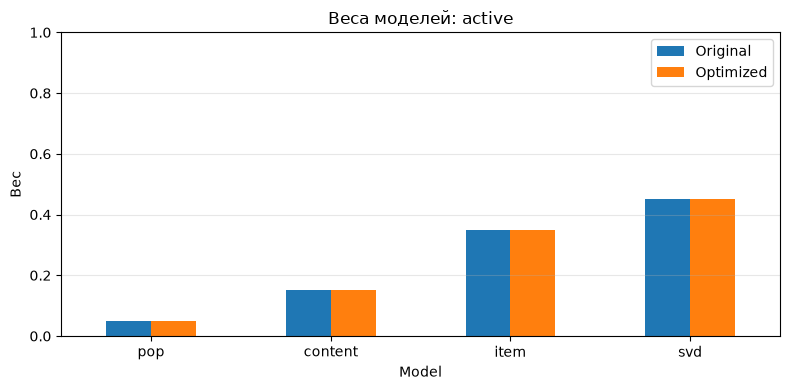

In [303]:
import matplotlib.pyplot as plt

for segment in optimized_weights:
    subset = weights_comparison[
        weights_comparison["Segment"] == segment
    ]

    subset.plot(
        x="Model",
        y=["Original", "Optimized"],
        kind="bar",
        figsize=(8, 4),
        rot=0
    )

    plt.title(f"Веса моделей: {segment}")
    plt.ylabel("Вес")
    plt.ylim(0, 1)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [304]:

def recommend_hybrid_optimized(user_id, N=10):
    user_type = get_user_type(user_id)

    if user_activity.get(user_id, 0) == 0:
        return recommend_popular(user_id, N=N)

    weights = optimized_weights[user_type]

    return recommend_hybrid(
        user_id=user_id,
        N=N,
        weights=weights,
        candidates_k=CANDIDATES_K
    )


In [305]:
user_id = 1

print("Сегмент:", get_user_type(user_id))
print("Веса:", optimized_weights[get_user_type(user_id)])

recommendations = recommend_hybrid_optimized(
    user_id=user_id,
    N=10
)

display(pd.DataFrame(recommendations))

Сегмент: new
Веса: {'pop': 0.20415604092367098, 'content': 0.033852559235602694, 'item': 0.5335531962338274, 'svd': 0.22843820360689895}


,book_id,score
0,9566,4.466251
1,4708,4.377816
2,9569,4.358657
3,3885,4.309390
4,2865,4.306607
5,5344,4.289893
6,2767,4.284655
7,7039,4.274008
8,9531,4.266710
9,9712,4.266225


In [306]:
def show_optimized_recommendations(user_id, N=10):
    recommendations = recommend_hybrid_optimized(
        user_id, N
    )

    result = pd.DataFrame(recommendations)

    result = result.merge(
        df_books[["id", "title", "authors"]],
        left_on="book_id",
        right_on="id",
        how="left"
    )

    return result[
        ["book_id", "title", "authors", "score"]
    ]


display(show_optimized_recommendations(user_id=1))

,book_id,title,authors,score
0,9566,Attack of the Deranged Mutant Killer Monster S...,Bill Watterson,4.466251
1,4708,BookRags Summary: A Storm of Swords,BookRags,4.377816
2,9569,The Hate U Give,Angie Thomas,4.358657
3,3885,Born a Crime: Stories From a South African Chi...,Trevor Noah,4.309390
4,2865,"The Gashlycrumb Tinies (The Vinegar Works, #1)",Edward Gorey,4.306607
5,5344,"A Game of Thrones: Comic Book, Issue 1","Daniel Abraham, George R.R. Martin, Tommy Patt...",4.289893
6,2767,"Saga, Vol. 3 (Saga, #3)","Brian K. Vaughan, Fiona Staples",4.284655
7,7039,The Brothers Lionheart,"Astrid Lindgren, Ilon Wikland, Jill M. Morgan",4.274008
8,9531,Crush,Richard Siken,4.266710
9,9712,"Magic Binds (Kate Daniels, #9)",Ilona Andrews,4.266225


In [307]:
comparison_models = {
    "Hybrid Weighted": recommend_hybrid,
    "Hybrid Adaptive": recommend_hybrid_adaptive,
    "Hybrid Optimized": recommend_hybrid_optimized
}

test_relevant = (
    test_df[test_df["rating"] >= 4]
    .groupby("user_id")["book_id"]
    .agg(set)
    .to_dict()
)

rng = np.random.default_rng(123)

test_users = rng.choice(
    list(test_relevant.keys()),
    size=min(200, len(test_relevant)),
    replace=False
).tolist()

results = []

for model_name, model_fn in comparison_models.items():
    metrics = evaluate_model(
        recommend_fn=model_fn,
        users=test_users,
        test_relevant=test_relevant,
        k=10
    )

    results.append({
        "Model": model_name,
        "Precision@10": metrics["precision"].mean(),
        "Recall@10": metrics["recall"].mean(),
        "nDCG@10": metrics["ndcg"].mean()
    })

final_comparison = pd.DataFrame(results)

display(
    final_comparison.sort_values(
        "nDCG@10",
        ascending=False
    )
)

,Model,Precision@10,Recall@10,nDCG@10
2,Hybrid Optimized,0.0055,0.029083,0.016908
1,Hybrid Adaptive,0.0045,0.019083,0.009934
0,Hybrid Weighted,0.0030,0.016000,0.007690


import json
from pathlib import Path

output_path = Path("artifacts/hybrid")
output_path.mkdir(parents=True, exist_ok=True)

with open(
    output_path / "optimized_weights.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        optimized_weights,
        f,
        indent=4,
        ensure_ascii=False
    )

with open(
    "artifacts/hybrid/optimized_weights.json",
    "r",
    encoding="utf-8"
) as f:
    optimized_weights = json.load(f)

In [ ]:
Этап 3. Оценка и оптимизация рекомендательной системы

In [309]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MODELS = {
    "Popularity": recommend_popular,
    "Content-Based": recommend_content,
    "Item-Based CF": recommend_item_cf,
    "SVD": recommend_svd,
    "Hybrid Weighted": recommend_hybrid,
    "Hybrid Adaptive": recommend_hybrid_adaptive,
    "Hybrid Optimized": recommend_hybrid_optimized
}

K = 10
RANDOM_STATE = 42


In [ ]:
test_relevant = (
    test_df[test_df["rating"] >= 4]
    .groupby("user_id")["book_id"]
    .agg(set)
    .to_dict()
)

In [310]:
rng = np.random.default_rng(RANDOM_STATE)

eval_users = rng.choice(
    list(test_relevant.keys()),
    size=min(200, len(test_relevant)),
    replace=False
).tolist()

print("Количество пользователей:", len(eval_users))

Количество пользователей: 200


In [311]:

def evaluate_recommender(model_fn, users, k=10):
    rows = []

    for user_id in users:
        actual = test_relevant[user_id]

        recommendations = model_fn(user_id, N=k)

        predicted = [
            item["book_id"]
            for item in recommendations
        ]

        rows.append({
            "user_id": user_id,
            "user_type": get_user_type(user_id),
            "precision": precision_at_k(actual, predicted, k),
            "recall": recall_at_k(actual, predicted, k),
            "ndcg": ndcg_at_k(actual, predicted, k),
            "recommendations_count": len(predicted)
        })

    return pd.DataFrame(rows)


In [312]:

def evaluate_recommender(model_fn, users, k=10):
    rows = []

    for user_id in users:
        actual = test_relevant[user_id]

        recommendations = model_fn(user_id, N=k)

        predicted = [
            item["book_id"]
            for item in recommendations
        ]

        rows.append({
            "user_id": user_id,
            "user_type": get_user_type(user_id),
            "precision": precision_at_k(actual, predicted, k),
            "recall": recall_at_k(actual, predicted, k),
            "ndcg": ndcg_at_k(actual, predicted, k),
            "recommendations_count": len(predicted)
        })

    return pd.DataFrame(rows)


In [313]:

from tqdm.auto import tqdm

evaluation_results = {}

for model_name, model_fn in tqdm(MODELS.items()):
    evaluation_results[model_name] = evaluate_recommender(
        model_fn,
        eval_users,
        k=K
    )

print("Оценка завершена")


  0%|          | 0/7 [00:00<?, ?it/s]

Оценка завершена


In [314]:

comparison_rows = []

for model_name, metrics in evaluation_results.items():
    comparison_rows.append({
        "Model": model_name,
        "Precision@10": metrics["precision"].mean(),
        "Recall@10": metrics["recall"].mean(),
        "nDCG@10": metrics["ndcg"].mean(),
        "Avg Recommendations": metrics["recommendations_count"].mean()
    })

comparison_df = (
    pd.DataFrame(comparison_rows)
    .sort_values("nDCG@10", ascending=False)
    .reset_index(drop=True)
)

display(comparison_df.round(4))


,Model,Precision@10,Recall@10,nDCG@10,Avg Recommendations
0,Hybrid Optimized,0.0035,0.0204,0.0120,10.0
1,Hybrid Adaptive,0.0020,0.0150,0.0085,10.0
2,Item-Based CF,0.0020,0.0175,0.0075,10.0
3,Hybrid Weighted,0.0020,0.0150,0.0065,10.0
4,Popularity,0.0010,0.0075,0.0042,10.0
5,SVD,0.0010,0.0075,0.0040,10.0
6,Content-Based,0.0015,0.0054,0.0040,10.0


In [315]:

comparison_rows = []

for model_name, metrics in evaluation_results.items():
    comparison_rows.append({
        "Model": model_name,
        "Precision@10": metrics["precision"].mean(),
        "Recall@10": metrics["recall"].mean(),
        "nDCG@10": metrics["ndcg"].mean(),
        "Avg Recommendations": metrics["recommendations_count"].mean()
    })

comparison_df = (
    pd.DataFrame(comparison_rows)
    .sort_values("nDCG@10", ascending=False)
    .reset_index(drop=True)
)

display(comparison_df.round(4))


,Model,Precision@10,Recall@10,nDCG@10,Avg Recommendations
0,Hybrid Optimized,0.0035,0.0204,0.0120,10.0
1,Hybrid Adaptive,0.0020,0.0150,0.0085,10.0
2,Item-Based CF,0.0020,0.0175,0.0075,10.0
3,Hybrid Weighted,0.0020,0.0150,0.0065,10.0
4,Popularity,0.0010,0.0075,0.0042,10.0
5,SVD,0.0010,0.0075,0.0040,10.0
6,Content-Based,0.0015,0.0054,0.0040,10.0


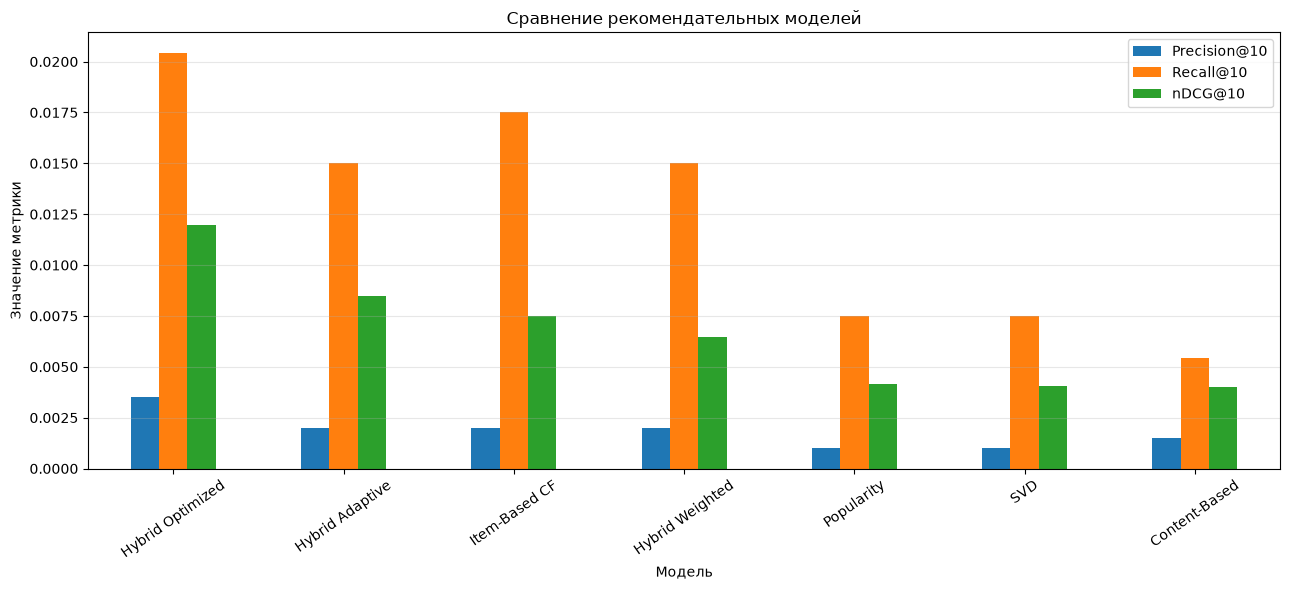

In [316]:

metrics_cols = [
    "Precision@10",
    "Recall@10",
    "nDCG@10"
]

ax = (
    comparison_df
    .set_index("Model")[metrics_cols]
    .plot(kind="bar", figsize=(13, 6), rot=35)
)

ax.set_title("Сравнение рекомендательных моделей")
ax.set_xlabel("Модель")
ax.set_ylabel("Значение метрики")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [317]:

base_names = [
    "Popularity",
    "Content-Based",
    "Item-Based CF",
    "SVD"
]

hybrid_names = [
    "Hybrid Weighted",
    "Hybrid Adaptive",
    "Hybrid Optimized"
]

best_base = (
    comparison_df[
        comparison_df["Model"].isin(base_names)
    ]
    .sort_values("nDCG@10", ascending=False)
    .iloc[0]
)

baseline_ndcg = best_base["nDCG@10"]

improvements = []

for model_name in hybrid_names:
    hybrid_ndcg = comparison_df.loc[
        comparison_df["Model"] == model_name,
        "nDCG@10"
    ].iloc[0]

    improvement = (
        (hybrid_ndcg - baseline_ndcg)
        / baseline_ndcg * 100
        if baseline_ndcg > 0 else np.nan
    )

    improvements.append({
        "Model": model_name,
        "Best Baseline": best_base["Model"],
        "Baseline nDCG": baseline_ndcg,
        "Hybrid nDCG": hybrid_ndcg,
        "Improvement (%)": improvement
    })

display(pd.DataFrame(improvements).round(4))


,Model,Best Baseline,Baseline nDCG,Hybrid nDCG,Improvement (%)
0,Hybrid Weighted,Item-Based CF,0.0075,0.0065,-13.8377
1,Hybrid Adaptive,Item-Based CF,0.0075,0.0085,12.9727
2,Hybrid Optimized,Item-Based CF,0.0075,0.0120,59.7926


In [318]:
segments_distribution = (
    evaluation_results["Popularity"]["user_type"]
    .value_counts()
    .reindex(["new", "regular", "active"], fill_value=0)
)

display(segments_distribution)

user_type
new        136
regular     64
active       0
Name: count, dtype: int64

In [319]:

segment_rows = []

for model_name, metrics in evaluation_results.items():
    grouped = (
        metrics.groupby("user_type")
        .agg(
            Users=("user_id", "count"),
            Precision=("precision", "mean"),
            Recall=("recall", "mean"),
            nDCG=("ndcg", "mean")
        )
        .reset_index()
    )

    grouped["Model"] = model_name

    segment_rows.append(grouped)

segment_comparison = pd.concat(
    segment_rows,
    ignore_index=True
)

display(
    segment_comparison[
        ["Model", "user_type", "Users",
         "Precision", "Recall", "nDCG"]
    ].round(4)
)


,Model,user_type,Users,Precision,Recall,nDCG
0,Popularity,new,136,0.0015,0.0110,0.0061
1,Popularity,regular,64,0.0000,0.0000,0.0000
2,Content-Based,new,136,0.0000,0.0000,0.0000
3,Content-Based,regular,64,0.0047,0.0169,0.0125
4,Item-Based CF,new,136,0.0029,0.0257,0.0110
5,Item-Based CF,regular,64,0.0000,0.0000,0.0000
6,SVD,new,136,0.0015,0.0110,0.0059
7,SVD,regular,64,0.0000,0.0000,0.0000
8,Hybrid Weighted,new,136,0.0022,0.0147,0.0058
9,Hybrid Weighted,regular,64,0.0016,0.0156,0.0078


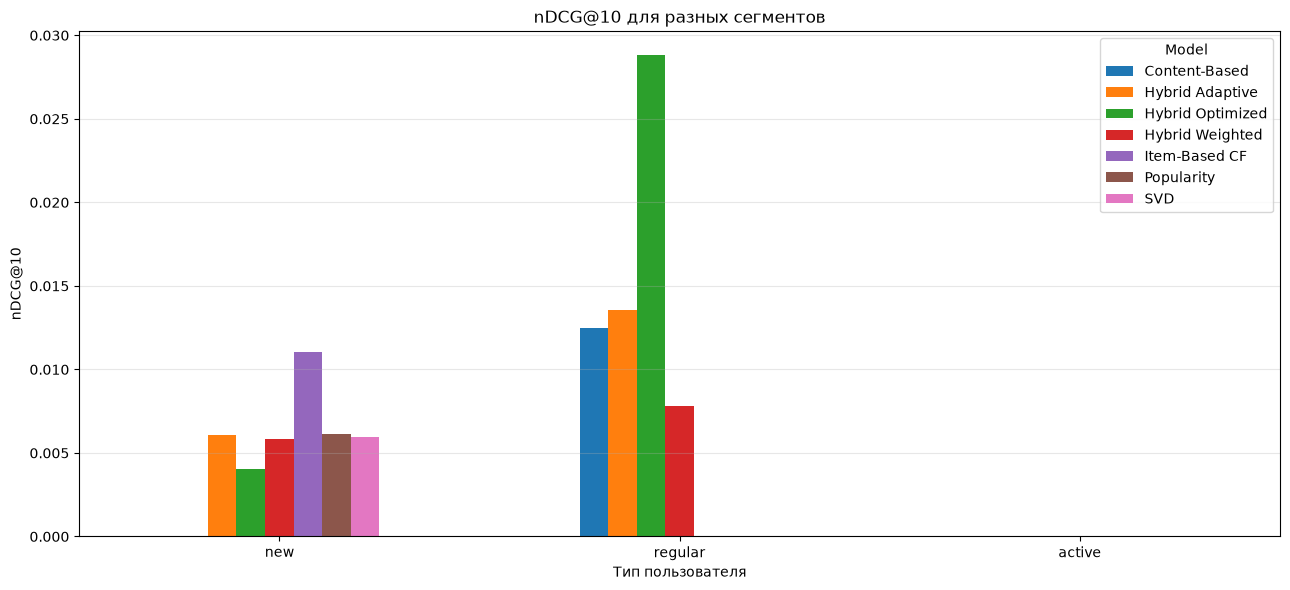

In [320]:

segment_pivot = segment_comparison.pivot(
    index="user_type",
    columns="Model",
    values="nDCG"
)

segment_pivot = segment_pivot.reindex(
    ["new", "regular", "active"]
)

ax = segment_pivot.plot(
    kind="bar",
    figsize=(13, 6),
    rot=0
)

ax.set_title("nDCG@10 для разных сегментов")
ax.set_xlabel("Тип пользователя")
ax.set_ylabel("nDCG@10")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [321]:

adaptive_segments = segment_comparison[
    segment_comparison["Model"] == "Hybrid Adaptive"
][["user_type", "nDCG"]].rename(
    columns={"nDCG": "Adaptive nDCG"}
)

optimized_segments = segment_comparison[
    segment_comparison["Model"] == "Hybrid Optimized"
][["user_type", "nDCG"]].rename(
    columns={"nDCG": "Optimized nDCG"}
)

segment_improvement = adaptive_segments.merge(
    optimized_segments,
    on="user_type"
)

segment_improvement["Improvement (%)"] = np.where(
    segment_improvement["Adaptive nDCG"] > 0,
    (
        segment_improvement["Optimized nDCG"]
        / segment_improvement["Adaptive nDCG"]
        - 1
    ) * 100,
    np.nan
)

display(segment_improvement.round(4))


,user_type,Adaptive nDCG,Optimized nDCG,Improvement (%)
0,new,0.0061,0.0040,-33.3257
1,regular,0.0136,0.0288,112.4430


In [322]:

weights_rows = []

for segment in ["new", "regular", "active"]:
    for model_name in ["pop", "content", "item", "svd"]:
        weights_rows.append({
            "Segment": segment,
            "Model": model_name,
            "Initial": ADAPTIVE_WEIGHTS[segment][model_name],
            "Optimized": optimized_weights[segment][model_name]
        })

weights_report = pd.DataFrame(weights_rows)

display(weights_report.round(4))


,Segment,Model,Initial,Optimized
0,new,pop,0.65,0.2042
1,new,content,0.25,0.0339
2,new,item,0.05,0.5336
3,new,svd,0.05,0.2284
4,regular,pop,0.15,0.0096
5,regular,content,0.35,0.4829
6,regular,item,0.25,0.2638
7,regular,svd,0.25,0.2437
8,active,pop,0.05,0.0500
9,active,content,0.15,0.1500


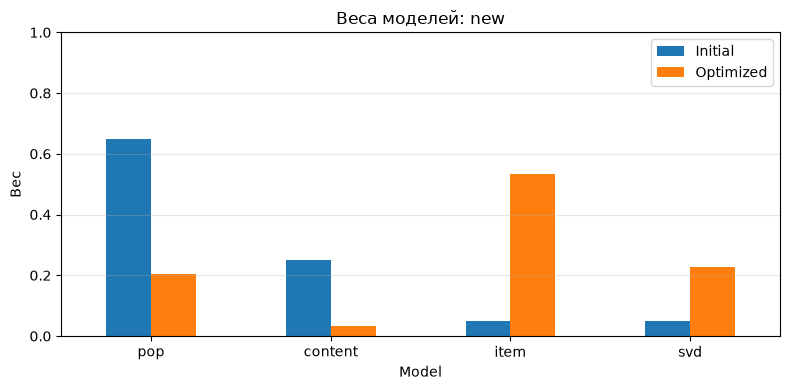

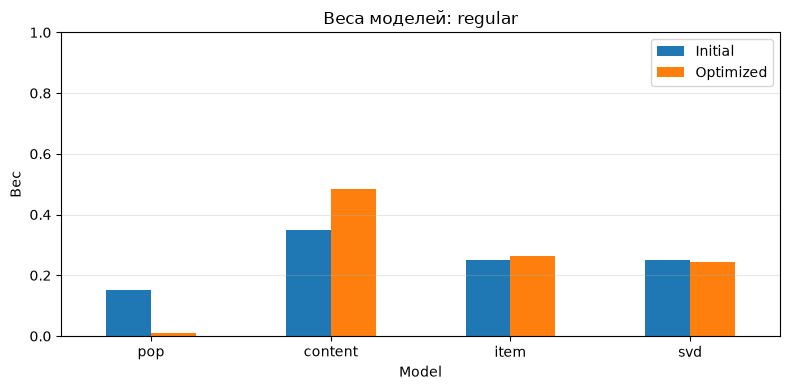

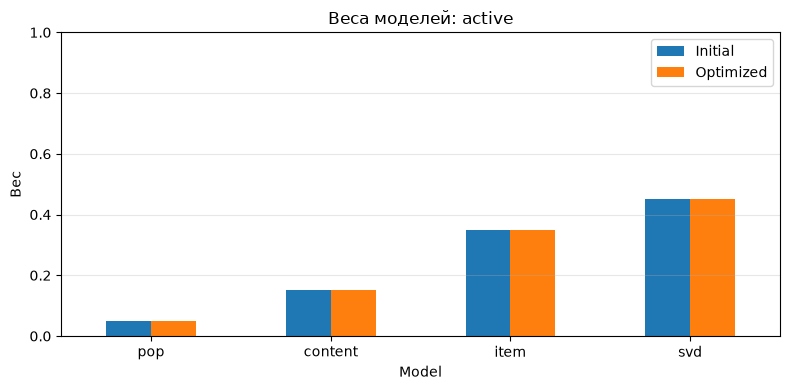

In [323]:

for segment in ["new", "regular", "active"]:
    segment_weights = weights_report[
        weights_report["Segment"] == segment
    ]

    ax = segment_weights.plot(
        x="Model",
        y=["Initial", "Optimized"],
        kind="bar",
        figsize=(8, 4),
        rot=0
    )

    ax.set_title(f"Веса моделей: {segment}")
    ax.set_ylabel("Вес")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()


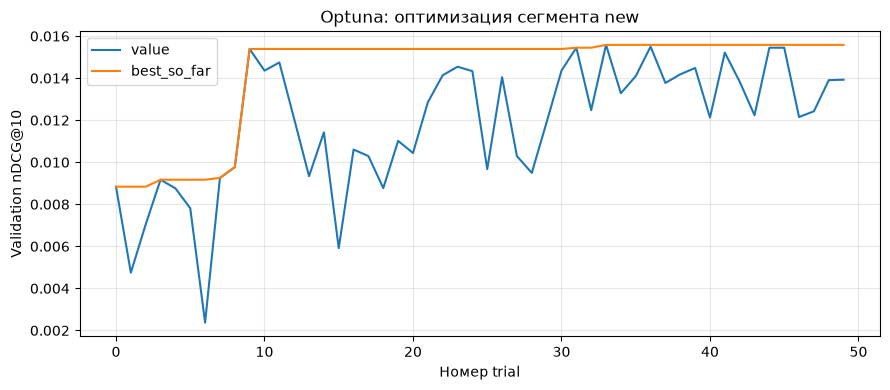

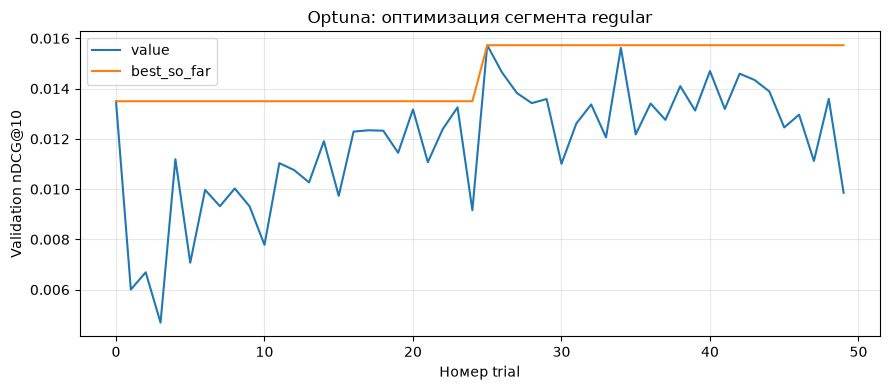

In [324]:

for segment, study in studies.items():

    trials = study.trials_dataframe()

    completed = trials[
        (trials["state"] == "COMPLETE")
        & trials["value"].notna()
    ].copy()

    if completed.empty:
        continue

    completed = completed.sort_values("number")

    completed["best_so_far"] = (
        completed["value"].cummax()
    )

    ax = completed.plot(
        x="number",
        y=["value", "best_so_far"],
        figsize=(9, 4)
    )

    ax.set_title(f"Optuna: оптимизация сегмента {segment}")
    ax.set_xlabel("Номер trial")
    ax.set_ylabel("Validation nDCG@10")
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


In [332]:

def bootstrap_ndcg_difference(
    results_a,
    results_b,
    n_bootstrap=2000,
    seed=42
):
    paired = results_a[
        ["user_id", "ndcg"]
    ].merge(
        results_b[["user_id", "ndcg"]],
        on="user_id",
        suffixes=("_a", "_b"),
        validate="one_to_one"
    )

    differences = (
        paired["ndcg_a"] - paired["ndcg_b"]
    ).to_numpy()

    if len(differences) == 0:
        raise ValueError("Нет общих пользователей")

    rng = np.random.default_rng(seed)

    bootstrap_means = np.array([
        rng.choice(
            differences,
            size=len(differences),
            replace=True
        ).mean()
        for _ in range(n_bootstrap)
    ])

    return {
        "mean_difference": differences.mean(),
        "ci_lower": np.percentile(bootstrap_means, 2.5),
        "ci_upper": np.percentile(bootstrap_means, 97.5)
    }


In [333]:
bootstrap_result = bootstrap_ndcg_difference(
    evaluation_results["Hybrid Optimized"],
    evaluation_results["SVD"]
)

display(pd.DataFrame([bootstrap_result]).round(5))

,mean_difference,ci_lower,ci_upper
0,0.00794,-0.00359,0.02088


In [334]:

from pathlib import Path
import json

output_dir = Path("artifacts/evaluation")
output_dir.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(
    output_dir / "models_comparison.csv",
    index=False
)

segment_comparison.to_csv(
    output_dir / "segment_comparison.csv",
    index=False
)

weights_report.to_csv(
    output_dir / "weights_comparison.csv",
    index=False
)

segment_improvement.to_csv(
    output_dir / "segment_improvement.csv",
    index=False
)

with open(
    output_dir / "optimized_weights.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        optimized_weights,
        f,
        ensure_ascii=False,
        indent=4
    )

print("Результаты сохранены:", output_dir)


Результаты сохранены: artifacts/evaluation


In [335]:

import numpy as np
import pandas as pd
import torch

from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# Сопоставление реальных ID с индексами эмбеддингов
user_ids_nn = np.sort(fit_df["user_id"].unique())
book_ids_nn = np.sort(df_books["id"].unique())

user_to_idx_nn = {
    int(uid): idx
    for idx, uid in enumerate(user_ids_nn)
}

book_to_idx_nn = {
    int(bid): idx
    for idx, bid in enumerate(book_ids_nn)
}

n_users = len(user_ids_nn)
n_books = len(book_ids_nn)

print("Users:", n_users)
print("Books:", n_books)


Device: cuda
Users: 28906
Books: 10000


In [336]:

class BookInteractionDataset(Dataset):
    def __init__(self, df, user_map, book_map, negative_ratio=1, seed=42):
        rng = np.random.default_rng(seed)

        df = df[
            df["user_id"].isin(user_map)
            & df["book_id"].isin(book_map)
        ].copy()

        observed = (
            df.groupby("user_id")["book_id"]
            .agg(set)
            .to_dict()
        )

        all_books = np.array(list(book_map.keys()), dtype=np.int64)
        examples = []

        for row in df.itertuples(index=False):
            uid = int(row.user_id)
            bid = int(row.book_id)
            label = float(row.rating >= 4)

            examples.append((
                user_map[uid],
                book_map[bid],
                label
            ))

            if label == 1.0:
                for _ in range(negative_ratio):
                    # Выбираем неизвестную пользователю книгу
                    for _attempt in range(100):
                        neg_bid = int(rng.choice(all_books))
                        if neg_bid not in observed[uid]:
                            examples.append((
                                user_map[uid],
                                book_map[neg_bid],
                                0.0
                            ))
                            break

        self.users = torch.tensor(
            [x[0] for x in examples], dtype=torch.long
        )
        self.books = torch.tensor(
            [x[1] for x in examples], dtype=torch.long
        )
        self.labels = torch.tensor(
            [x[2] for x in examples], dtype=torch.float32
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return (
            self.users[idx],
            self.books[idx],
            self.labels[idx]
        )


In [337]:
train_dataset_nn = BookInteractionDataset(
    fit_df,
    user_to_idx_nn,
    book_to_idx_nn,
    negative_ratio=1
)

train_loader_nn = DataLoader(
    train_dataset_nn,
    batch_size=1024,
    shuffle=True,
    pin_memory=(device.type == "cuda")
)

print("Обучающих пар:", len(train_dataset_nn))

Обучающих пар: 109986


In [338]:

class TwoTowerModel(nn.Module):
    def __init__(
        self,
        n_users,
        n_books,
        embedding_dim=64,
        hidden_dim=128
    ):
        super().__init__()

        self.user_tower = nn.Sequential(
            nn.Embedding(n_users, embedding_dim),
            nn.Linear(embedding_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, embedding_dim)
        )

        self.item_tower = nn.Sequential(
            nn.Embedding(n_books, embedding_dim),
            nn.Linear(embedding_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, embedding_dim)
        )

    def forward(self, user_ids, book_ids):
        user_embeddings = self.user_tower(user_ids)
        book_embeddings = self.item_tower(book_ids)

        # Скалярное произведение эмбеддингов
        scores = (
            user_embeddings * book_embeddings
        ).sum(dim=1)

        return scores


In [339]:
two_tower_model = TwoTowerModel(
    n_users=n_users,
    n_books=n_books,
    embedding_dim=64,
    hidden_dim=128
).to(device)

print(two_tower_model)

TwoTowerModel(
  (user_tower): Sequential(
    (0): Embedding(28906, 64)
    (1): Linear(in_features=64, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
  )
  (item_tower): Sequential(
    (0): Embedding(10000, 64)
    (1): Linear(in_features=64, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
  )
)


In [340]:

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    two_tower_model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

EPOCHS = 10
train_losses = []

for epoch in range(EPOCHS):
    two_tower_model.train()

    total_loss = 0.0
    total_samples = 0

    for users, books, labels in train_loader_nn:
        users = users.to(device)
        books = books.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = two_tower_model(users, books)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        batch_size = len(labels)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

    epoch_loss = total_loss / total_samples
    train_losses.append(epoch_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} "
        f"| Train Loss: {epoch_loss:.4f}"
    )


Epoch 1/10 | Train Loss: 0.6585
Epoch 2/10 | Train Loss: 0.5139
Epoch 3/10 | Train Loss: 0.4404
Epoch 4/10 | Train Loss: 0.4177
Epoch 5/10 | Train Loss: 0.4056
Epoch 6/10 | Train Loss: 0.3918
Epoch 7/10 | Train Loss: 0.3762
Epoch 8/10 | Train Loss: 0.3543
Epoch 9/10 | Train Loss: 0.3246
Epoch 10/10 | Train Loss: 0.2850


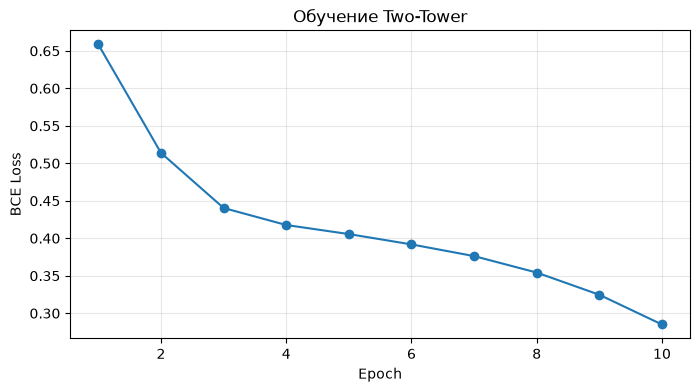

In [341]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Обучение Two-Tower")
plt.grid(alpha=0.3)
plt.show()

In [342]:

two_tower_model.eval()

with torch.no_grad():
    all_book_indices = torch.arange(
        n_books,
        device=device
    )

    all_book_embeddings = (
        two_tower_model.item_tower(all_book_indices)
    )

print("Размер эмбеддингов книг:", all_book_embeddings.shape)


Размер эмбеддингов книг: torch.Size([10000, 64])


In [343]:

def recommend_two_tower(user_id, N=10):
    # Холодный старт
    if user_id not in user_to_idx_nn:
        return recommend_popular(user_id, N)

    user_idx = user_to_idx_nn[user_id]

    two_tower_model.eval()

    with torch.no_grad():
        user_tensor = torch.tensor(
            [user_idx],
            dtype=torch.long,
            device=device
        )

        user_embedding = two_tower_model.user_tower(
            user_tensor
        )

        scores = (
            user_embedding @ all_book_embeddings.T
        ).squeeze(0).cpu().numpy().copy()

    # Исключаем книги, оценённые при обучении
    seen = user_history.get(user_id, set())

    for book_id in seen:
        idx = book_to_idx_nn.get(book_id)
        if idx is not None:
            scores[idx] = -np.inf

    top_indices = np.argsort(scores)[::-1][:N]

    return [
        {
            "book_id": int(book_ids_nn[idx]),
            "score": float(scores[idx])
        }
        for idx in top_indices
        if np.isfinite(scores[idx])
    ]


In [344]:
recommendations = recommend_two_tower(user_id=1, N=10)

display(pd.DataFrame(recommendations))

,book_id,score
0,9566,4.466251
1,4708,4.377816
2,9569,4.358657
3,3885,4.309390
4,2865,4.306607
5,5344,4.289893
6,2767,4.284655
7,7039,4.274008
8,9531,4.266710
9,9712,4.266225


In [345]:
two_tower_df = pd.DataFrame(recommendations)

display(
    two_tower_df.merge(
        df_books[["id", "title", "authors"]],
        left_on="book_id",
        right_on="id",
        how="left"
    )[["book_id", "title", "authors", "score"]]
)

,book_id,title,authors,score
0,9566,Attack of the Deranged Mutant Killer Monster S...,Bill Watterson,4.466251
1,4708,BookRags Summary: A Storm of Swords,BookRags,4.377816
2,9569,The Hate U Give,Angie Thomas,4.358657
3,3885,Born a Crime: Stories From a South African Chi...,Trevor Noah,4.309390
4,2865,"The Gashlycrumb Tinies (The Vinegar Works, #1)",Edward Gorey,4.306607
5,5344,"A Game of Thrones: Comic Book, Issue 1","Daniel Abraham, George R.R. Martin, Tommy Patt...",4.289893
6,2767,"Saga, Vol. 3 (Saga, #3)","Brian K. Vaughan, Fiona Staples",4.284655
7,7039,The Brothers Lionheart,"Astrid Lindgren, Ilon Wikland, Jill M. Morgan",4.274008
8,9531,Crush,Richard Siken,4.266710
9,9712,"Magic Binds (Kate Daniels, #9)",Ilona Andrews,4.266225


In [346]:
two_tower_metrics = evaluate_recommender(
    recommend_two_tower,
    eval_users,
    k=10
)

two_tower_summary = {
    "Model": "Two-Tower",
    "Precision@10": two_tower_metrics["precision"].mean(),
    "Recall@10": two_tower_metrics["recall"].mean(),
    "nDCG@10": two_tower_metrics["ndcg"].mean(),
    "Avg Recommendations": two_tower_metrics[
        "recommendations_count"
    ].mean()
}

display(pd.DataFrame([two_tower_summary]))

,Model,Precision@10,Recall@10,nDCG@10,Avg Recommendations
0,Two-Tower,0.0015,0.006667,0.004658,10.0


In [347]:
comparison_nn = pd.concat(
    [
        comparison_df,
        pd.DataFrame([two_tower_summary])
    ],
    ignore_index=True
)

comparison_nn = comparison_nn.sort_values(
    "nDCG@10",
    ascending=False
)

display(comparison_nn.round(4))

,Model,Precision@10,Recall@10,nDCG@10,Avg Recommendations
0,Hybrid Optimized,0.0035,0.0204,0.0120,10.0
1,Hybrid Adaptive,0.0020,0.0150,0.0085,10.0
2,Item-Based CF,0.0020,0.0175,0.0075,10.0
3,Hybrid Weighted,0.0020,0.0150,0.0065,10.0
7,Two-Tower,0.0015,0.0067,0.0047,10.0
4,Popularity,0.0010,0.0075,0.0042,10.0
5,SVD,0.0010,0.0075,0.0040,10.0
6,Content-Based,0.0015,0.0054,0.0040,10.0


In [348]:
comparison_nn = pd.concat(
    [
        comparison_df,
        pd.DataFrame([two_tower_summary])
    ],
    ignore_index=True
)

comparison_nn = comparison_nn.sort_values(
    "nDCG@10",
    ascending=False
)

display(comparison_nn.round(4))

,Model,Precision@10,Recall@10,nDCG@10,Avg Recommendations
0,Hybrid Optimized,0.0035,0.0204,0.0120,10.0
1,Hybrid Adaptive,0.0020,0.0150,0.0085,10.0
2,Item-Based CF,0.0020,0.0175,0.0075,10.0
3,Hybrid Weighted,0.0020,0.0150,0.0065,10.0
7,Two-Tower,0.0015,0.0067,0.0047,10.0
4,Popularity,0.0010,0.0075,0.0042,10.0
5,SVD,0.0010,0.0075,0.0040,10.0
6,Content-Based,0.0015,0.0054,0.0040,10.0


In [349]:

HYBRID_NN_WEIGHTS = {
    "pop": 0.08,
    "content": 0.16,
    "item": 0.24,
    "svd": 0.32,
    "two_tower": 0.20
}

BASE_MODELS_NN = {
    "pop": recommend_popular,
    "content": recommend_content,
    "item": recommend_item_cf,
    "svd": recommend_svd,
    "two_tower": recommend_two_tower
}


def recommend_hybrid_nn(
    user_id,
    N=10,
    weights=None,
    candidates_k=100
):
    if weights is None:
        weights = HYBRID_NN_WEIGHTS

    if set(weights) != set(BASE_MODELS_NN):
        raise ValueError("Не совпадают названия моделей")

    if not np.isclose(sum(weights.values()), 1.0):
        raise ValueError("Сумма весов должна быть равна 1")

    model_predictions = {
        name: recommend_fn(
            user_id,
            N=candidates_k
        )
        for name, recommend_fn in BASE_MODELS_NN.items()
    }

    normalized = {
        name: normalize_scores(predictions)
        for name, predictions in model_predictions.items()
    }

    candidates = set().union(
        *(scores.keys() for scores in normalized.values())
    )

    seen = user_history.get(user_id, set())
    candidates -= seen

    results = []

    for book_id in candidates:
        score = sum(
            weights[name] * normalized[name].get(book_id, 0.0)
            for name in weights
        )

        results.append({
            "book_id": int(book_id),
            "score": float(score)
        })

    results.sort(
        key=lambda x: (-x["score"], x["book_id"])
    )

    return results[:N]


In [350]:

HYBRID_NN_WEIGHTS = {
    "pop": 0.08,
    "content": 0.16,
    "item": 0.24,
    "svd": 0.32,
    "two_tower": 0.20
}

BASE_MODELS_NN = {
    "pop": recommend_popular,
    "content": recommend_content,
    "item": recommend_item_cf,
    "svd": recommend_svd,
    "two_tower": recommend_two_tower
}


def recommend_hybrid_nn(
    user_id,
    N=10,
    weights=None,
    candidates_k=100
):
    if weights is None:
        weights = HYBRID_NN_WEIGHTS

    if set(weights) != set(BASE_MODELS_NN):
        raise ValueError("Не совпадают названия моделей")

    if not np.isclose(sum(weights.values()), 1.0):
        raise ValueError("Сумма весов должна быть равна 1")

    model_predictions = {
        name: recommend_fn(
            user_id,
            N=candidates_k
        )
        for name, recommend_fn in BASE_MODELS_NN.items()
    }

    normalized = {
        name: normalize_scores(predictions)
        for name, predictions in model_predictions.items()
    }

    candidates = set().union(
        *(scores.keys() for scores in normalized.values())
    )

    seen = user_history.get(user_id, set())
    candidates -= seen

    results = []

    for book_id in candidates:
        score = sum(
            weights[name] * normalized[name].get(book_id, 0.0)
            for name in weights
        )

        results.append({
            "book_id": int(book_id),
            "score": float(score)
        })

    results.sort(
        key=lambda x: (-x["score"], x["book_id"])
    )

    return results[:N]


In [351]:
recommendations = recommend_hybrid_nn(
    user_id=1,
    N=10
)

display(pd.DataFrame(recommendations))

,book_id,score
0,9566,1.000000
1,4708,0.792815
2,9569,0.740643
3,2865,0.628159
4,3885,0.625697
5,2767,0.593092
6,5344,0.568268
7,9531,0.532688
8,7039,0.525978
9,6862,0.507879


In [352]:

from tqdm.auto import tqdm

MODEL_NAMES_NN = tuple(BASE_MODELS_NN.keys())

prediction_cache_nn = {}

for user_id in tqdm(all_optimization_users):
    prediction_cache_nn[user_id] = {}

    for name, model_fn in BASE_MODELS_NN.items():
        recommendations = model_fn(
            user_id,
            N=100
        )

        prediction_cache_nn[user_id][name] = (
            normalize_scores(recommendations)
        )


  0%|          | 0/400 [00:00<?, ?it/s]

In [353]:
def recommend_from_cache_nn(user_id, weights, N=10):
    scores_by_model = prediction_cache_nn[user_id]

    candidates = set().union(
        *(scores.keys() for scores in scores_by_model.values())
    )

    candidates -= user_history.get(user_id, set())

    scores = []

    for book_id in candidates:
        hybrid_score = sum(
            weights[name] * scores_by_model[name].get(book_id, 0.0)
            for name in MODEL_NAMES_NN
        )

        scores.append((book_id, hybrid_score))

    scores.sort(key=lambda x: (-x[1], x[0]))

    return [book_id for book_id, _ in scores[:N]]

In [354]:

import optuna

def objective_nn(trial, users):
    raw_weights = {
        name: trial.suggest_float(
            f"w_{name}",
            0.0,
            1.0
        )
        for name in MODEL_NAMES_NN
    }

    total = sum(raw_weights.values())

    if total <= 0:
        return 0.0

    weights = {
        name: value / total
        for name, value in raw_weights.items()
    }

    ndcg_values = []

    for user_id in users:
        predicted = recommend_from_cache_nn(
            user_id,
            weights,
            N=10
        )

        ndcg_values.append(
            ndcg_at_k(
                val_relevant[user_id],
                predicted,
                k=10
            )
        )

    return float(np.mean(ndcg_values))


In [355]:

studies_nn = {}
optimized_weights_nn = {}

# Fallback: исходные веса для сегментов без данных
def extend_weights(old_weights, nn_weight=0.20):
    weights = {
        name: value * (1 - nn_weight)
        for name, value in old_weights.items()
    }
    weights["two_tower"] = nn_weight
    return weights


for segment, users in optimization_users.items():
    if not users:
        optimized_weights_nn[segment] = extend_weights(
            ADAPTIVE_WEIGHTS[segment]
        )
        continue

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=42)
    )

    study.optimize(
        lambda trial: objective_nn(trial, users),
        n_trials=50,
        show_progress_bar=True
    )

    studies_nn[segment] = study

    best = study.best_params
    total = sum(best.values())

    optimized_weights_nn[segment] = {
        name: best[f"w_{name}"] / total
        for name in MODEL_NAMES_NN
    }

    print(
        segment,
        "Validation nDCG@10:",
        round(study.best_value, 4)
    )
    print(optimized_weights_nn[segment])


  0%|          | 0/50 [00:00<?, ?it/s]

new Validation nDCG@10: 0.0123
{'pop': 0.15191795120338522, 'content': 0.05218465289381058, 'item': 0.33211538315751954, 'svd': 0.1753136831221636, 'two_tower': 0.28846832962312097}


  0%|          | 0/50 [00:00<?, ?it/s]

regular Validation nDCG@10: 0.014
{'pop': 0.04462004953446298, 'content': 0.439697765170287, 'item': 0.3307275681182397, 'svd': 0.1476796428477299, 'two_tower': 0.03727497432928036}


In [356]:

def recommend_hybrid_nn_optimized(user_id, N=10):
    if user_activity.get(user_id, 0) == 0:
        return recommend_popular(user_id, N=N)

    segment = get_user_type(user_id)

    return recommend_hybrid_nn(
        user_id=user_id,
        N=N,
        weights=optimized_weights_nn[segment],
        candidates_k=100
    )


In [357]:

FINAL_MODELS = {
    "Popularity": recommend_popular,
    "Content-Based": recommend_content,
    "Item-Based CF": recommend_item_cf,
    "SVD": recommend_svd,
    "Two-Tower": recommend_two_tower,
    "Hybrid Weighted": recommend_hybrid,
    "Hybrid Adaptive": recommend_hybrid_adaptive,
    "Hybrid Optimized": recommend_hybrid_optimized,
    "Hybrid NN": recommend_hybrid_nn,
    "Hybrid NN Optimized": recommend_hybrid_nn_optimized
}

final_evaluation = {}
final_rows = []

# Используем один и тот же список eval_users
for name, model_fn in tqdm(FINAL_MODELS.items()):
    metrics = evaluate_recommender(
        model_fn,
        eval_users,
        k=10
    )

    final_evaluation[name] = metrics

    final_rows.append({
        "Model": name,
        "Precision@10": metrics["precision"].mean(),
        "Recall@10": metrics["recall"].mean(),
        "nDCG@10": metrics["ndcg"].mean()
    })

final_df = (
    pd.DataFrame(final_rows)
    .sort_values("nDCG@10", ascending=False)
)

display(final_df.round(4))


  0%|          | 0/10 [00:00<?, ?it/s]

,Model,Precision@10,Recall@10,nDCG@10
9,Hybrid NN Optimized,0.0030,0.0200,0.0125
7,Hybrid Optimized,0.0035,0.0204,0.0120
6,Hybrid Adaptive,0.0020,0.0150,0.0085
2,Item-Based CF,0.0020,0.0175,0.0075
5,Hybrid Weighted,0.0020,0.0150,0.0065
8,Hybrid NN,0.0020,0.0150,0.0062
4,Two-Tower,0.0015,0.0067,0.0047
0,Popularity,0.0010,0.0075,0.0042
3,SVD,0.0010,0.0075,0.0040
1,Content-Based,0.0015,0.0054,0.0040


In [358]:
pairs = [
    ("Two-Tower", "SVD"),
    ("Hybrid NN", "Hybrid Weighted"),
    ("Hybrid NN Optimized", "Hybrid Optimized")
]

comparison = final_df.set_index("Model")

improvement_rows = []

for new_name, base_name in pairs:
    new_score = comparison.loc[new_name, "nDCG@10"]
    base_score = comparison.loc[base_name, "nDCG@10"]

    improvement_rows.append({
        "New Model": new_name,
        "Baseline": base_name,
        "Delta nDCG": new_score - base_score,
        "Improvement (%)": (
            100 * (new_score / base_score - 1)
            if base_score > 0 else np.nan
        )
    })

display(pd.DataFrame(improvement_rows).round(4))

,New Model,Baseline,Delta nDCG,Improvement (%)
0,Two-Tower,SVD,0.0006,15.5076
1,Hybrid NN,Hybrid Weighted,-0.0003,-4.3862
2,Hybrid NN Optimized,Hybrid Optimized,0.0005,4.3597


In [359]:
segment_rows_nn = []

for name, metrics in final_evaluation.items():
    grouped = metrics.groupby("user_type").agg(
        users=("user_id", "count"),
        precision=("precision", "mean"),
        recall=("recall", "mean"),
        ndcg=("ndcg", "mean")
    )

    for segment, row in grouped.iterrows():
        segment_rows_nn.append({
            "Model": name,
            "Segment": segment,
            "Users": int(row["users"]),
            "nDCG@10": row["ndcg"]
        })

segment_nn_df = pd.DataFrame(segment_rows_nn)

display(
    segment_nn_df.pivot(
        index="Segment",
        columns="Model",
        values="nDCG@10"
    ).round(4)
)

Model,Content-Based,Hybrid Adaptive,Hybrid NN,Hybrid NN Optimized,Hybrid Optimized,Hybrid Weighted,Item-Based CF,Popularity,SVD,Two-Tower
Segment,,,,,,,,,,
new,0.0000,0.0061,0.0062,0.0077,0.0040,0.0058,0.011,0.0061,0.0059,0.0013
regular,0.0125,0.0136,0.0060,0.0226,0.0288,0.0078,0.000,0.0000,0.0000,0.0118


In [360]:
from pathlib import Path
import json

output_dir = Path("artifacts/two_tower")
output_dir.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state_dict": two_tower_model.state_dict(),
        "user_to_idx": user_to_idx_nn,
        "book_to_idx": book_to_idx_nn,
        "embedding_dim": 64,
        "hidden_dim": 128
    },
    output_dir / "two_tower.pt"
)

with open(
    output_dir / "hybrid_nn_weights.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        optimized_weights_nn,
        f,
        indent=4,
        ensure_ascii=False
    )

final_df.to_csv(
    output_dir / "final_model_comparison.csv",
    index=False
)